# Numerical experiments for the spiked Haar covariance model

Model: $\Sigma_p = A_p + O_p B_p O_p^* + \sigma^2 I_p$ with $O_p$ Haar on $O(p)$ (real case)
or $U(p)$ (complex case), and, conditionally on $O_p$, $n$ i.i.d. centred Gaussian vectors
with covariance $\Sigma_p$.

Throughout this notebook $r = s = 1$, $\alpha_1 = 10$, $\beta_1 = 5$, $\sigma^2 = 1$,
and we track the largest spike $\theta_1 = \alpha_1 = 10$.

**Finite-$(p,n)$ reference law.** Theorem `t:main` gives, at the scale $p$ and for
$p^2/n \to \tau \in [0,\infty)$,
$$p\bigl(\hat\lambda_{p,\ell} - \phi_{p/n}(\theta_\ell)\bigr) \xrightarrow{\ \mathrm{law}\ }
W_\ell + \sqrt{\kappa \tau V_0(\theta_\ell)}\, G_\ell .$$
At finite $(p, n)$ we compare the empirical fluctuation to
$$L_{p,n} := W_\ell + \sqrt{\kappa\,\tfrac{p^2}{n}\, V_{p/n}(\theta_\ell)}\; G_\ell ,$$
that is, the same law with $\tau$ replaced by $p^2/n$ and $V_0$ by $V_{p/n}$. This single
law is the correct reference in the four regimes: when $p^2/n \to 0$ it reduces to
$W_\ell$; when $p^2/n \to \tau \in (0,\infty)$ it is the mixed law; and when
$p^2/n \to \infty$, dividing it by $p/\sqrt n$ gives the Bai--Yao Gaussian
$\sqrt{\kappa V_c(\theta_\ell)}\,G_\ell$ of Theorems `t:infy` and `t:prop`.

At the scale $\sqrt n$ the reference law is $(\sqrt n / p) L_{p,n}
= \sqrt{n/p^2}\, W_\ell + \sqrt{\kappa V_{p/n}(\theta_\ell)}\, G_\ell$, which is
Proposition `p:mixed` at finite $\tau$.

**On divergence.** At a fixed $(p, n)$ nothing diverges: divergence is a property of a
sequence. What the figures show is the mechanism behind it. On the $\sqrt n$ row, the
weight $\sqrt{n/p^2}$ in front of $W_\ell$ grows as $p^2/n$ decreases, so the histogram
widens and becomes skewed; on the $p$ row, the Gaussian standard deviation
$\sqrt{\kappa (p^2/n) V}$ grows as $p^2/n$ increases. Each panel also shows, as a grey
dotted curve, the *pure* limit of its regime (the Gaussian alone on the $\sqrt n$ row,
$W_\ell$ alone on the $p$ row), so one sees directly which term is negligible where.

In [36]:
# Imports and global configuration
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance, norm, gaussian_kde
from scipy.sparse.linalg import eigsh, LinearOperator
from tqdm.auto import tqdm

%matplotlib inline


In [22]:
SEED    = 42
sigma2  = 1.0

# ---- model parameters (r = s = 1) ----
ALPHAS = np.array([10.0])
BETAS  = np.array([5.0])
ELL    = 0                       # rank of the tracked spike: 0 -> theta = 10
THETA  = 10.0

# ---- the four (p, n) configurations, one per column of the figures ----
CONFIGS = [
    (2500, 2500),    # col 1: proportional regime, c = 1
    (500,  5000),    # col 2: p/n -> 0, p^2/n large
    (500,  50000),   # col 3: p^2/n = 5
    (100,  50000),   # col 4: p^2/n = 0.2
]
MODES = ['orthogonal', 'unitary']

# ---- Monte Carlo budget ----
# N_SIM is the number of replications of the model per (config, mode).
# Reduce it (or reduce p and n in CONFIGS) if the run is too long.
N_SIM   = 2000
N_MC    = 100000   # draws used to render the theoretical densities

FAST_ENGINE = False   # see the section "Simulation engines" below

for (p, n) in CONFIGS:
    print(f"p = {p:5d}  n = {n:6d}   c = p/n = {p/n:8.4f}   p^2/n = {p*p/n:10.3f}")

p =  2500  n =   2500   c = p/n =   1.0000   p^2/n =   2500.000
p =   500  n =   5000   c = p/n =   0.1000   p^2/n =     50.000
p =   500  n =  50000   c = p/n =   0.0100   p^2/n =      5.000
p =   100  n =  50000   c = p/n =   0.0020   p^2/n =      0.200


## Theoretical formulas

In [23]:
def phi(theta, c, sigma2=1.0):
    "phi_c(theta) = (sigma^2 + theta)(1 + c sigma^2 / theta), the asymptotic spike location."
    return (sigma2 + theta) * (1.0 + c * sigma2 / theta)

def V_func(theta, c, sigma2=1.0):
    "V_c(theta) = (sigma^2 + theta)^2 (1 - c sigma^4 / theta^2), the Bai-Yao variance factor."
    return (sigma2 + theta) ** 2 * (1.0 - c * sigma2 ** 2 / theta ** 2)

def kappa_of(mode):
    "kappa = 2 in the real case, 1 in the complex case."
    return 1 if mode == 'unitary' else 2

## Haar samplers

In [24]:
def sample_haar_orthogonal(p, rng):
    "Haar measure on O(p) (Mezzadri 2007)."
    G = rng.standard_normal((p, p))
    Q, R = np.linalg.qr(G)
    D = np.sign(np.diag(R)); D[D == 0] = 1
    return Q * D

def sample_haar_unitary(p, rng):
    "Haar measure on U(p) (Mezzadri 2007)."
    G = (rng.standard_normal((p, p)) + 1j * rng.standard_normal((p, p))) / np.sqrt(2)
    Q, R = np.linalg.qr(G)
    d = np.diag(R)
    return Q * (d / np.abs(d))

def gauss(shape, mode, rng):
    "Standard real, or standard circular complex, Gaussian array."
    if mode == 'unitary':
        p, n = shape
        Z = rng.standard_normal((p, 2 * n)).view(np.complex128)
        Z *= 1.0 / np.sqrt(2.0)
        return Z
    return rng.standard_normal(shape)

def sample_haar_block(p, r, s, mode, rng):
    "Exact r x s truncation of a Haar matrix, in O(p s^2) instead of O(p^3)."
    # The first s columns of a Haar matrix have the law of the Q factor of a p x s
    # Gaussian matrix, with the sign / phase convention above.
    G = gauss((p, s), mode, rng)
    Q, R = np.linalg.qr(G)
    d = np.diag(R)
    if mode == 'unitary':
        Q = Q * (d / np.abs(d)).conj()
    else:
        sg = np.sign(d); sg[sg == 0] = 1.0
        Q = Q * sg
    return Q[:r, :]

## The limit laws $W_\ell$ and $L_{p,n}$

For the sum model $P(A, B) = A + B$ and $\theta_\ell = \alpha_i$,
$$W_\ell = \sum_{j=1}^s \frac{\alpha_i \beta_j}{\alpha_i - \beta_j}\,|g_{ij}|^2 ,$$
with $|g_{ij}|^2$ i.i.d. $\chi^2_1$ in the real case and i.i.d. $\mathrm{Exp}(1)$ in the
complex case; the roles of $\alpha$ and $\beta$ are exchanged when
$\theta_\ell = \beta_j$. With $r = s = 1$, $\alpha = 10$, $\beta = 5$ this is
$W_1 = 10\,|g|^2$.

In [25]:
def _W_coeffs(theta_k, alphas, betas):
    "Coefficients of W_ell as a weighted sum of |g|^2 variables."
    eps = 1e-9
    alphas = np.asarray(alphas, float); betas = np.asarray(betas, float)
    if np.any(np.abs(theta_k - alphas) < eps):
        a_i = float(alphas[np.argmin(np.abs(theta_k - alphas))])
        return np.array([a_i * b / (a_i - b) for b in betas])
    if np.any(np.abs(theta_k - betas) < eps):
        b_j = float(betas[np.argmin(np.abs(theta_k - betas))])
        return np.array([a * b_j / (b_j - a) for a in alphas])
    raise ValueError(f"theta = {theta_k} is neither an alpha nor a beta")

def sample_W_ell(theta_k, alphas, betas, mode, N, rng):
    "Direct Monte Carlo draws of W_ell."
    coeffs = _W_coeffs(theta_k, alphas, betas)
    K = len(coeffs)
    G2 = (rng.exponential(1.0, (N, K)) if mode == 'unitary'
          else rng.standard_normal((N, K)) ** 2)
    return G2 @ coeffs

def var_W_ell(theta_k, alphas, betas, mode):
    "Var(W_ell): Var(chi^2_1) = 2 in the real case, Var(Exp(1)) = 1 in the complex case."
    coeffs = _W_coeffs(theta_k, alphas, betas)
    return float((1.0 if mode == 'unitary' else 2.0) * np.sum(coeffs ** 2))

def gaussian_sd_p(theta_k, p, n, sigma2, mode):
    "Standard deviation of the Gaussian part of L_{p,n}, at the scale p."
    V = V_func(theta_k, p / n, sigma2)
    return np.sqrt(max(kappa_of(mode) * (p * p / n) * V, 0.0))

def sample_reference(theta_k, alphas, betas, p, n, sigma2, mode, N, rng, scale='p'):
    "Draws of the finite-(p,n) reference law, at the scale p or at the scale sqrt(n)."
    L = (sample_W_ell(theta_k, alphas, betas, mode, N, rng)
         + gaussian_sd_p(theta_k, p, n, sigma2, mode) * rng.standard_normal(N))
    return L if scale == 'p' else L * np.sqrt(n) / p

## Simulation engines

`run_haar_full` is the direct construction: it draws $O_p$, forms
$\Sigma_p = A_p + O_p B_p O_p^* + \sigma^2 I_p$, factorises it and builds the sample
covariance matrix. It costs $O(p^3 + p^2 n)$ per replication.

`run_haar_fast` returns **the same law** at a much lower cost, using two reductions.
First, $A_p + O_p B_p O_p^* = Q_p D Q_p^*$ with
$Q_p = [a_1,\ldots,a_r,\,O_pb_1,\ldots,O_pb_s]$ and
$D = \mathrm{diag}(\alpha, \beta)$, so its non-zero eigenvalues are those of the
$(r+s)\times(r+s)$ matrix $D^{1/2}(Q_p^*Q_p)D^{1/2}$, which depends on $O_p$ only through
the $r \times s$ block of overlaps $a_i^*O_pb_j$. Second, by Lemma `l:cond`, conditionally
on $O_p$ the eigenvalues of $\hat\Sigma_p$ have the law of those of
$\Lambda_p^{1/2}(n^{-1}Z_pZ_p^*)\Lambda_p^{1/2}$, and only the top $r+s$ of them are
needed, which a matrix-free Lanczos solver returns without ever forming a $p\times p$
matrix. The cell after the engines checks that the two agree.

In [26]:
def population_spikes(alphas, betas, Ohat):
    "Non-zero eigenvalues of A + O B O^*, from the r x s block of overlaps."
    r, s = len(alphas), len(betas)
    D = np.concatenate([np.asarray(alphas, float), np.asarray(betas, float)])
    M = np.eye(r + s, dtype=Ohat.dtype)
    M[:r, r:] = Ohat
    M[r:, :r] = Ohat.conj().T
    M = np.sqrt(D)[:, None] * M * np.sqrt(D)[None, :]
    return np.sort(np.linalg.eigvalsh(M))[::-1]

DENSE_MAX_P = 600   # below this, forming the p x p matrix is faster than Lanczos

def top_sample_eigs(lam, n, K, mode, rng, tol=1e-8):
    "Top K eigenvalues of Lambda^{1/2}(Z Z^* / n)Lambda^{1/2}."
    p = len(lam); sq = np.sqrt(lam)
    Z = gauss((p, n), mode, rng)
    if p <= DENSE_MAX_P:
        Y = sq[:, None] * Z
        S = (Y @ Y.conj().T) / n
        return np.sort(np.linalg.eigvalsh(S).real)[::-1][:K]
    def mv(v):
        return sq * (Z @ (Z.conj().T @ (sq * v))) / n
    dt = np.complex128 if mode == 'unitary' else np.float64
    v0 = np.zeros(p, dtype=dt); v0[:K] = 1.0
    op = LinearOperator((p, p), matvec=mv, dtype=dt)
    return np.sort(eigsh(op, k=K, which='LA', tol=tol, v0=v0,
                         return_eigenvectors=False).real)[::-1]

def run_haar_fast(alphas, betas, p, n, sigma2, mode, N_sim, rng, progress=tqdm):
    alphas = np.asarray(alphas, float); betas = np.asarray(betas, float)
    r, s = len(alphas), len(betas); K = r + s
    pop = np.zeros((N_sim, K)); samp = np.zeros((N_sim, K))
    for i in progress(range(N_sim)):
        Ohat = sample_haar_block(p, r, s, mode, rng)
        mu = population_spikes(alphas, betas, Ohat)
        pop[i] = mu
        lam = np.full(p, float(sigma2)); lam[:K] = sigma2 + mu
        samp[i] = top_sample_eigs(lam, n, K, mode, rng)
    theta = np.sort(np.concatenate([alphas, betas]))[::-1]
    return theta, pop, samp

def run_haar_full(alphas, betas, p, n, sigma2, mode, N_sim, rng, chunk=10000, progress=tqdm):
    r, s = len(alphas), len(betas); K = r + s
    F = np.complex128 if mode == 'unitary' else np.float64
    A = np.zeros((p, p), dtype=F); B = np.zeros((p, p), dtype=F)
    A[np.arange(r), np.arange(r)] = alphas
    B[r + np.arange(s), r + np.arange(s)] = betas
    Ip = np.eye(p, dtype=F)
    pop = np.zeros((N_sim, K)); samp = np.zeros((N_sim, K))
    for it in progress(range(N_sim)):
        O = sample_haar_unitary(p, rng) if mode == 'unitary' else sample_haar_orthogonal(p, rng)
        Sigma = A + O @ B @ O.conj().T + sigma2 * Ip
        pop[it] = np.sort(np.linalg.eigvalsh(Sigma).real)[::-1][:K] - sigma2
        L = np.linalg.cholesky(Sigma)
        S = np.zeros((p, p), dtype=F); remaining = n
        while remaining > 0:
            m = min(chunk, remaining)
            X = L @ gauss((p, m), mode, rng)
            S += X @ X.conj().T
            remaining -= m
        S /= n
        samp[it] = np.sort(np.linalg.eigvalsh(S).real)[::-1][:K]
    theta = np.sort(np.concatenate([alphas, betas]))[::-1]
    return theta, pop, samp

run_haar = run_haar_fast if FAST_ENGINE else run_haar_full

In [27]:
# Check that the two engines produce the same law (small p, n so that the full one is cheap)
from scipy.stats import ks_2samp

def check_engines(p=60, n=200, N=3000):
    rows = []
    for mode in MODES:
        _, pf, sf = run_haar_fast(ALPHAS, BETAS, p, n, sigma2, mode, N,
                                  np.random.default_rng(11), progress=lambda x: x)
        _, pr, sr = run_haar_full(ALPHAS, BETAS, p, n, sigma2, mode, N,
                                  np.random.default_rng(22), progress=lambda x: x)
        for k, th in enumerate(np.sort(np.concatenate([ALPHAS, BETAS]))[::-1]):
            rows.append((mode, th,
                         ks_2samp(pf[:, k], pr[:, k]).pvalue,
                         ks_2samp(sf[:, k], sr[:, k]).pvalue))
    print(f"Kolmogorov-Smirnov p-values, fast vs full engine  (p={p}, n={n}, N={N})")
    print(f"{'mode':<12}{'theta':>7}{'population':>13}{'sample':>10}")
    for mode, th, a, b in rows:
        print(f"{mode:<12}{th:>7.1f}{a:>13.3f}{b:>10.3f}")

check_engines()

Kolmogorov-Smirnov p-values, fast vs full engine  (p=60, n=200, N=3000)
mode          theta   population    sample
orthogonal     10.0        0.051     0.523
orthogonal      5.0        0.051     0.443
unitary        10.0        0.716     0.737
unitary         5.0        0.716     0.502


## Experiment 1 — histograms of $\sqrt n\,(\hat\lambda_{p,\ell} - \phi_{p/n}(\theta_\ell))$

Two rows (real, complex) by four columns (the four $(p,n)$ configurations), at the spike
$\theta = 10$. Red dashed: the finite-$(p,n)$ reference law
$\sqrt{n/p^2}\,W_\ell + \sqrt{\kappa V_{p/n}}\,G_\ell$. Grey dotted: the pure Gaussian
$\mathcal N(0, \kappa V_{p/n}(\theta_\ell))$, which is the limit in the first two columns.

In [28]:
# Run the simulations once; experiments 1 and 2 are two views of the same data.
SIM = {}
for j, (p, n) in enumerate(CONFIGS):
    for mode in MODES:
        rng = np.random.default_rng(SEED + 1000 * j + (7 if mode == 'unitary' else 0))
        print(f"simulating  p={p}, n={n}, {mode}, N_sim={N_SIM}")
        theta_vec, pop, samp = run_haar(ALPHAS, BETAS, p, n, sigma2, mode, N_SIM, rng)
        SIM[(j, mode)] = samp
THETA_VEC = np.sort(np.concatenate([ALPHAS, BETAS]))[::-1]
print("done")

simulating  p=2500, n=2500, orthogonal, N_sim=2000


  0%|          | 0/2000 [00:00<?, ?it/s]

simulating  p=2500, n=2500, unitary, N_sim=2000


  0%|          | 0/2000 [00:00<?, ?it/s]

simulating  p=500, n=5000, orthogonal, N_sim=2000


  0%|          | 0/2000 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/2000 [00:00<?, ?it/s]

simulating  p=100, n=50000, unitary, N_sim=2000


  0%|          | 0/2000 [00:00<?, ?it/s]

done


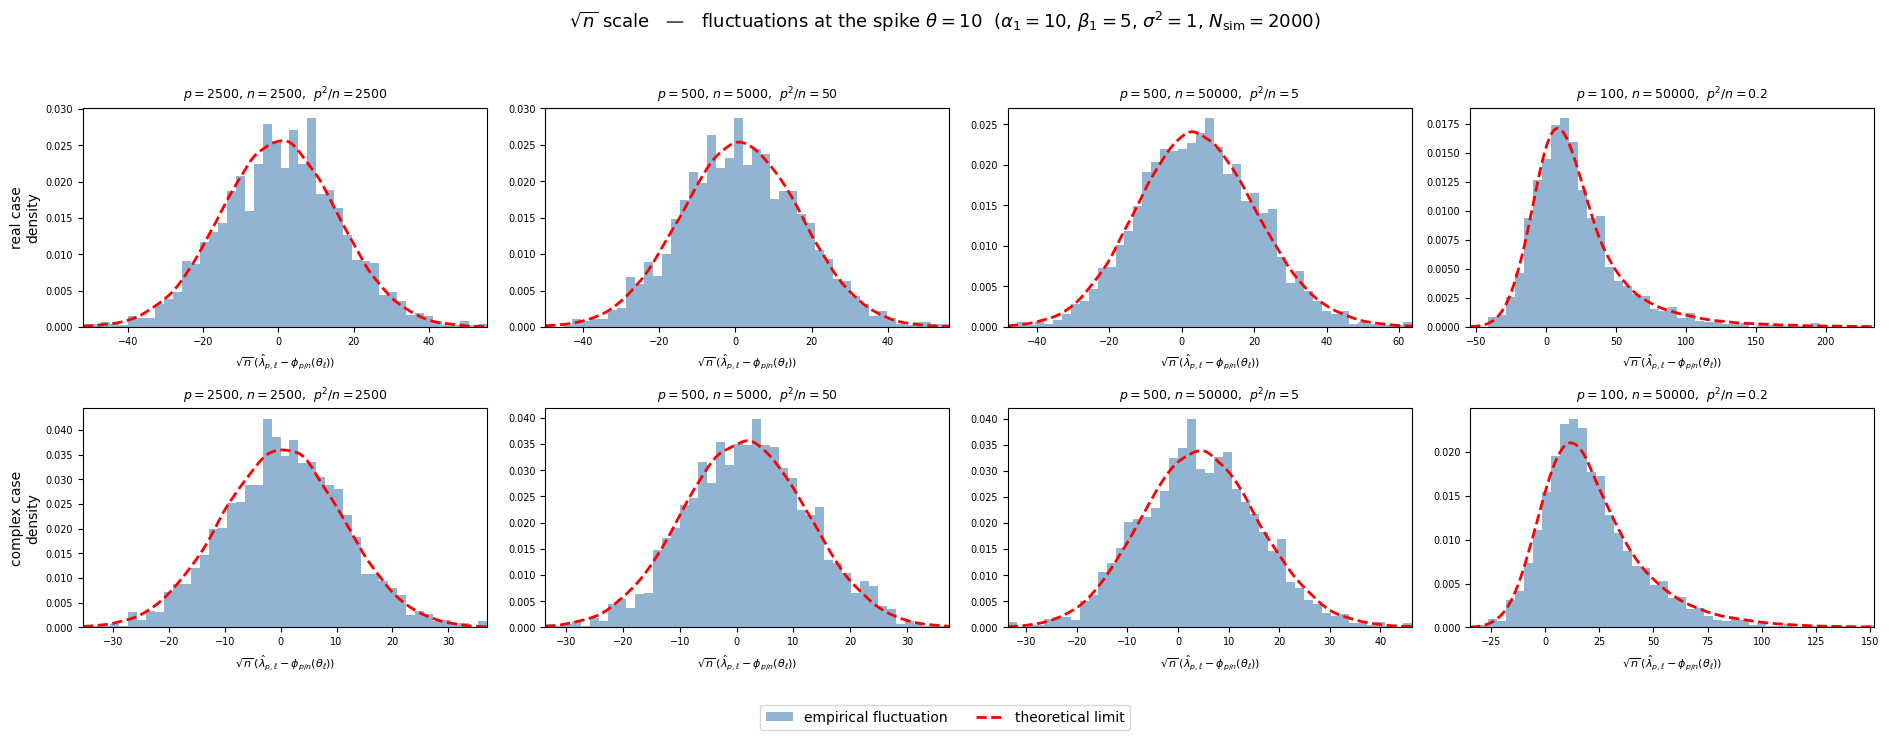

In [62]:
def hist_panel(ax, fluct, ref, title, xlabel):
    "One panel: empirical histogram and the reference density (red)."
    # range driven by robust quantiles of both samples, so a few outliers do not
    # flatten the histogram
    lo = min(np.quantile(fluct, 0.002), np.quantile(ref, 0.002))
    hi = max(np.quantile(fluct, 0.998), np.quantile(ref, 0.998))
    pad = 0.06 * (hi - lo); lo -= pad; hi += pad
    bins = np.linspace(lo, hi, 46)
    xs = np.linspace(lo, hi, 400)

    ax.hist(np.clip(fluct, lo, hi), bins=bins, density=True, alpha=0.6,
            color='steelblue', label='empirical fluctuation')
    ax.plot(xs, gaussian_kde(ref, bw_method=0.12)(xs), 'r--', lw=2,
            label='theoretical limit')
    ax.set_xlim(lo, hi)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(xlabel, fontsize=8)
    ax.tick_params(labelsize=7)


def figure_histograms(scale):
    "scale = 'sqrt_n' or 'p'."
    fig, axes = plt.subplots(2, 4, figsize=(19, 7.2))
    rng_ref = np.random.default_rng(SEED + 999)
    handles = None

    for i, mode in enumerate(MODES):
        for j, (p, n) in enumerate(CONFIGS):
            ax = axes[i, j]
            c, tau = p / n, p * p / n
            samp = SIM[(j, mode)]
            centre = phi(THETA, c, sigma2)

            if scale == 'sqrt_n':
                fluct = np.sqrt(n) * (samp[:, ELL] - centre)
                ref = sample_reference(THETA, ALPHAS, BETAS, p, n, sigma2, mode,
                                       N_MC, rng_ref, scale='sqrt_n')
                xlab = r'$\sqrt{n}\,(\hat\lambda_{p,\ell}-\phi_{p/n}(\theta_\ell))$'
            else:
                fluct = p * (samp[:, ELL] - centre)
                ref = sample_reference(THETA, ALPHAS, BETAS, p, n, sigma2, mode,
                                       N_MC, rng_ref, scale='p')
                xlab = r'$p\,(\hat\lambda_{p,\ell}-\phi_{p/n}(\theta_\ell))$'

            title = rf'$p={p}$, $n={n}$,  $p^2/n={tau:g}$'
            hist_panel(ax, fluct, ref, title, xlab)
            if handles is None:
                handles, labels = ax.get_legend_handles_labels()

        axes[i, 0].set_ylabel(('real case' if mode == 'orthogonal' else 'complex case')
                              + '\ndensity', fontsize=10)

    head = (r'$\sqrt{n}$ scale' if scale == 'sqrt_n' else r'$p$ scale')
    fig.suptitle(head + rf'   —   fluctuations at the spike $\theta={THETA:g}$'
                 rf'  ($\alpha_1={ALPHAS[0]:g}$, $\beta_1={BETAS[0]:g}$,'
                 rf' $\sigma^2={sigma2:g}$, $N_{{\rm sim}}={N_SIM}$)', fontsize=13)
    fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=10,
               bbox_to_anchor=(0.5, -0.03))
    fig.tight_layout(rect=[0, 0.04, 1, 0.95])
    return fig

fig1 = figure_histograms('sqrt_n')
plt.show()

**Reading the figure.** Columns 1 and 2 have $p^2/n$ large, so the weight
$\sqrt{n/p^2}$ in front of $W_\ell$ is small: the red and the grey curves coincide, and the
limit is the Bai--Yao Gaussian of Theorems `t:prop`(ii) and `t:infy`. In columns 3 and 4
this weight is $1/\sqrt5 \approx 0.45$ and $1/\sqrt{0.2} \approx 2.24$: the red curve
separates from the grey one, shifts to the right and becomes skewed, and the standard
deviation grows. This is the finite-$(p,n)$ form of the divergence at the $\sqrt n$ scale
stated in Proposition `p:diverge`(i): along a sequence with $p^2/n \to 0$, the factor
$\sqrt{n/p^2}$ tends to infinity and no limit remains.

## Experiment 2 — histograms of $p\,(\hat\lambda_{p,\ell} - \phi_{p/n}(\theta_\ell))$

Same data, same layout. Red dashed: the reference law
$L_{p,n} = W_\ell + \sqrt{\kappa (p^2/n) V_{p/n}}\,G_\ell$. 

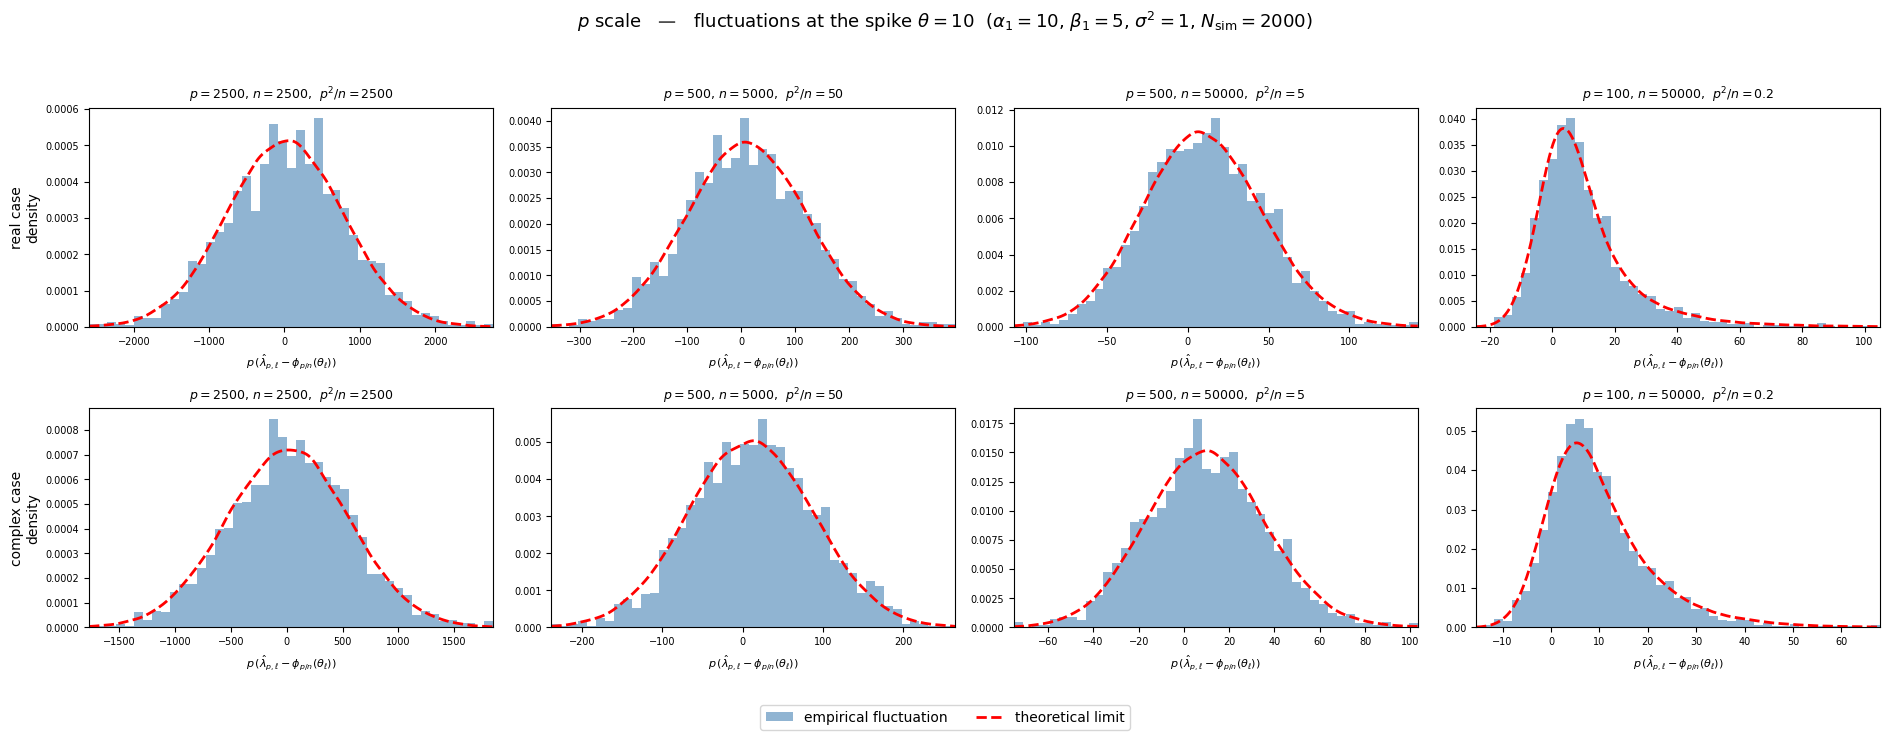

In [63]:
fig2 = figure_histograms('p')
plt.show()

**Reading the figure.** Now the roles are exchanged. In columns 1 and 2 the Gaussian
standard deviation $\sqrt{\kappa (p^2/n) V}$ is large, the red curve is a wide Gaussian and
$W_\ell$ (grey) is invisible next to it: this is the finite-$(p,n)$ form of the divergence
of the scaling by $p$, Proposition `p:diverge`(ii) and (iii). In column 3 ($p^2/n = 5$) the
two components are of comparable size and the red curve is the convolution of Theorem
`t:main`. In column 4 ($p^2/n = 0.2$) the Gaussian part has almost disappeared and the red
curve is close to $W_\ell$ alone, that is, to the Haar-dominated limit.

## Experiment 3 — speed of convergence across the three regimes

The three regimes have three different limits, so comparing the empirical fluctuation to a
single fixed law would only make sense in one regime at a time. We use instead the
finite-$(p,n)$ reference law $L_{p,n}$ defined at the top of the notebook, which is valid
in all of them, and we **normalise both samples by its standard deviation**
$$s_{p,n} = \sqrt{\operatorname{Var}(W_\ell) + \kappa \tfrac{p^2}{n} V_{p/n}(\theta_\ell)} .$$
After this normalisation every quantity is of order one in every regime, so the distances
are comparable from one end of the grid to the other.

We then plot, against $p^2/n$ on a logarithmic axis, the distance between the normalised
fluctuation and three candidate limits:

* $W_\ell$ alone, the Haar-dominated limit ($p^2/n \to 0$);
* the Gaussian alone, the sample-dominated limit ($p^2/n \to \infty$);
* $L_{p,n}$, the unified reference law.

The third curve should stay at the noise floor everywhere, while each of the first two
should reach the floor only inside its own regime and rise outside it. A single figure then
shows the whole transition and why the three regimes have to be separated.

In [44]:
# Grid for experiment 3
MODE_C   = 'orthogonal'
N_FIXED  = 20000
P_GRID   = [10,20,30, 50, 80, 120, 200, 300, 450, 700,1000,1500]
N_SIM_C  = 2000
N_MC_C   = 20000
N_FLOOR  = 20     # bootstrap replications for the noise floor

for p in P_GRID:
    print(f"p = {p:4d}   p^2/n = {p*p/N_FIXED:8.3f}   c = {p/N_FIXED:.4f}")

p =   10   p^2/n =    0.005   c = 0.0005
p =   20   p^2/n =    0.020   c = 0.0010
p =   30   p^2/n =    0.045   c = 0.0015
p =   50   p^2/n =    0.125   c = 0.0025
p =   80   p^2/n =    0.320   c = 0.0040
p =  120   p^2/n =    0.720   c = 0.0060
p =  200   p^2/n =    2.000   c = 0.0100
p =  300   p^2/n =    4.500   c = 0.0150
p =  450   p^2/n =   10.125   c = 0.0225
p =  700   p^2/n =   24.500   c = 0.0350
p = 1000   p^2/n =   50.000   c = 0.0500
p = 1500   p^2/n =  112.500   c = 0.0750


In [45]:
kappa_C = kappa_of(MODE_C)
varW_C  = var_W_ell(THETA, ALPHAS, BETAS, MODE_C)

def wasserstein1(x, y):
    return wasserstein_distance(x, y)

def mmd_squared(x, y, sigma=None, max_n=800, seed=0):
    "Unbiased MMD^2 with a Gaussian kernel and median-heuristic bandwidth."
    x = np.asarray(x, float); y = np.asarray(y, float)
    r = np.random.default_rng(seed)
    if len(x) > max_n: x = r.choice(x, max_n, replace=False)
    if len(y) > max_n: y = r.choice(y, max_n, replace=False)
    m, n_ = len(x), len(y)
    if sigma is None:
        z = np.concatenate([x, y])
        d = np.abs(z[:, None] - z[None, :]); d = d[d > 0]
        sigma = float(np.median(d)) if len(d) else 1.0
        if sigma == 0: sigma = 1.0
    g = 1.0 / (2 * sigma ** 2)
    Kxx = np.exp(-g * (x[:, None] - x[None, :]) ** 2)
    Kyy = np.exp(-g * (y[:, None] - y[None, :]) ** 2)
    Kxy = np.exp(-g * (x[:, None] - y[None, :]) ** 2)
    np.fill_diagonal(Kxx, 0); np.fill_diagonal(Kyy, 0)
    return Kxx.sum()/(m*(m-1)) + Kyy.sum()/(n_*(n_-1)) - 2*Kxy.mean()

LAB_W = r'Haar limit $W_\ell$'
LAB_G = r'Gaussian limit'
LAB_L = r'unified law $L_{p,n}$'
LABELS = [LAB_W, LAB_G, LAB_L]

def candidates(p, n, rng_ref, N):
    """The three candidate limits, normalised by the sd of L_{p,n}."""
    sdG = gaussian_sd_p(THETA, p, n, sigma2, MODE_C)
    s   = np.sqrt(varW_C + sdG ** 2)
    W   = sample_W_ell(THETA, ALPHAS, BETAS, MODE_C, N, rng_ref)
    G   = rng_ref.standard_normal(N)
    return s, {LAB_W: W / s, LAB_G: sdG * G / s, LAB_L: (W + sdG * G) / s}

res_W = {k: [] for k in LABELS}; res_M = {k: [] for k in LABELS}
floor_W, floor_M, taus = [], [], []

for p in tqdm(P_GRID, desc="experiment 3"):
    n = N_FIXED
    taus.append(p * p / n)

    # empirical fluctuation at the scale p, normalised
    rng_sim = np.random.default_rng(SEED * 1000 + p)
    _, _, samp = run_haar(ALPHAS, BETAS, p, n, sigma2, MODE_C, N_SIM_C, rng_sim,
                          progress=lambda x: x)
    rng_ref = np.random.default_rng(SEED + 1)
    s, cand = candidates(p, n, rng_ref, N_MC_C)
    emp = p * (samp[:, ELL] - phi(THETA, p / n, sigma2)) / s

    for k in LABELS:
        res_W[k].append(wasserstein1(emp, cand[k]))
        res_M[k].append(mmd_squared(emp, cand[k]))

    # noise floor: an independent sample of L_{p,n} of size N_SIM_C, against cand[LAB_L]
    w_s, m_s = [], []
    for b in range(N_FLOOR):
        rb = np.random.default_rng(SEED + 4321 + 17 * b + p)
        _, cb = candidates(p, n, rb, N_SIM_C)
        w_s.append(wasserstein1(cb[LAB_L], cand[LAB_L]))
        m_s.append(max(0.0, mmd_squared(cb[LAB_L], cand[LAB_L], seed=b)))
    floor_W.append(float(np.mean(w_s))); floor_M.append(float(np.mean(m_s)))

taus = np.array(taus)
print("done")

experiment 3:   0%|          | 0/12 [00:00<?, ?it/s]

done


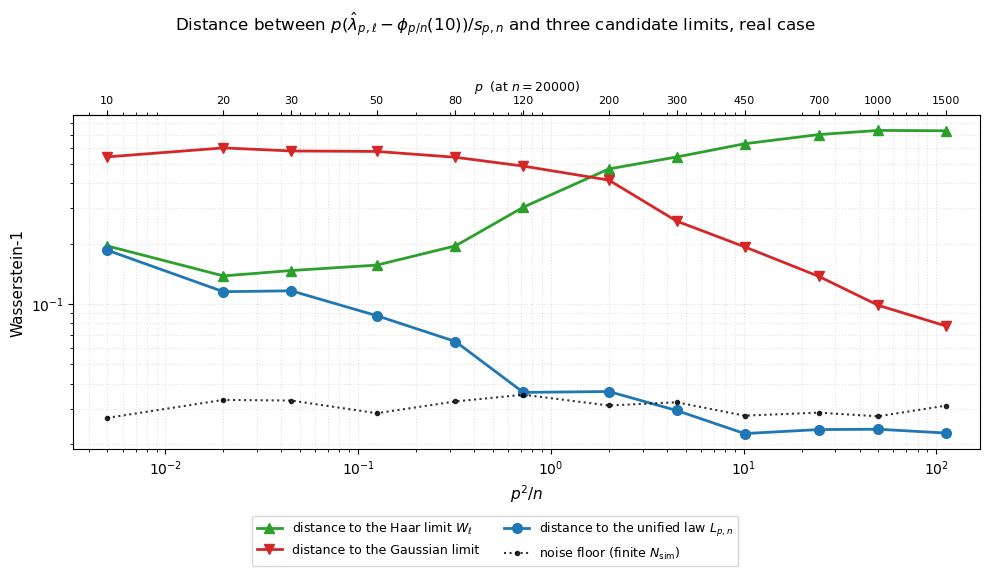

In [61]:
COLORS  = {LAB_W: 'tab:green', LAB_G: 'tab:red', LAB_L: 'tab:blue'}
MARKERS = {LAB_W: '^',         LAB_G: 'v',       LAB_L: 'o'}

fig3, ax = plt.subplots(1, 1, figsize=(10, 5))

for k in LABELS:
    ax.plot(taus, res_W[k], MARKERS[k] + '-', lw=2, ms=7, color=COLORS[k],
            label='distance to the ' + k)

ax.plot(taus, floor_W, 'k:', lw=1.5, marker='.', ms=6, alpha=0.8,
        label=r'noise floor (finite $N_{\rm sim}$)')

ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'$p^2/n$', fontsize=11)
ax.set_ylabel('Wasserstein-1', fontsize=11)
ax.grid(True, which='both', ls=':', alpha=0.35)
ax.set_xlim(taus.min() / 1.5, taus.max() * 1.5)

sec = ax.secondary_xaxis('top')
sec.set_xticks(taus)
sec.set_xticklabels([str(p) for p in P_GRID], fontsize=8)
sec.set_xlabel(r'$p$  (at $n = %d$)' % N_FIXED, fontsize=9)

handles, labels = ax.get_legend_handles_labels()
fig3.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.02),
            ncol=2, fontsize=9, frameon=True)

fig3.suptitle(r'Distance between $p(\hat\lambda_{p,\ell}-\phi_{p/n}(10))/s_{p,n}$'
              r' and three candidate limits, real case', fontsize=12, y=1.02)
fig3.tight_layout()
plt.show()

**Reading the figure.** The blue curve, which uses the unified reference law
$L_{p,n}$, stays at the noise floor over the whole range of $p^2/n$: this is the numerical
content of Theorem `t:main`. The green curve ($W_\ell$ alone) sits on the floor only on the
left, where $p^2/n$ is small, and rises once the Gaussian part is no longer negligible; the
red curve (Gaussian alone) does the opposite. The crossing region is the mixed regime
$p^2/n \asymp 1$, where neither of the two pure limits is correct and both terms are needed.

The noise floor is the distance between two independent samples of the same law, at the
same sizes $N_{\rm sim}$ and $N_{\rm MC}$; a curve that reaches it cannot be distinguished
from the truth at this Monte Carlo budget.

To extend the figure, add a second value of $n$ (a second pair of panels, or a second set of
curves), and enlarge `P_GRID` to reach the proportional regime $p/n \to c > 0$, which sits
at the far right of the axis.